In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import importlib
if 'src.data_processing' in sys.modules:
    import src.data_processing
    importlib.reload(src.data_processing)
if 'src.modeling' in sys.modules:
    import src.modeling
    importlib.reload(src.modeling)
from src.modeling import ModelBenchmark, get_feature_importance
from src.data_processing import load_processed_data
import pandas as pd
import matplotlib.pyplot as plt



In [2]:
df = load_processed_data(r"data\processed\features_data_encoded.csv")

Wczytywanie danych z: C:\Users\aiszk\PycharmProjects\PythonProject\data\processed\features_data_encoded.csv
✓ Wczytano 4,484,722 wierszy, 57 kolumn


In [3]:
# Drop non-features columns
drop_cols = ['timestamp', 'meter_id', 'campus_id', 'consumption', 'date_dt', 'id', 'id_building', 'id_campus']
drop_cols = [col for col in drop_cols if col in df.columns]

X = df.drop(drop_cols, axis=1)
y = df['consumption']

# Usuń kolumny kategoryczne (strings)
categorical_cols = X.select_dtypes(include=['object']).columns
print(f"Kolumny kategoryczne: {list(categorical_cols)}")

X = X.drop(categorical_cols, axis=1)

# Sprawdzenie czy nie ma NaN
print(f"Braki danych: {X.isnull().sum().sum()}")
if X.isnull().sum().sum() > 0:
    X = X.fillna(X.mean())
    print("✓ Braki uzupełnione średnią")

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"Typ danych X:\n{X.dtypes}")

# Split train/test (80/20 temporal)
split_idx = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"Train: {X_train.shape}")
print(f"Test:  {X_test.shape}")

Kolumny kategoryczne: []
Braki danych: 0
X shape: (4484722, 55)
y shape: (4484722,)
Typ danych X:
built_year                      float64
gross_floor_area                float64
room_area                       float64
capacity                        float64
capacity_campus                   int64
apparent_temperature            float64
air_temperature                 float64
dew_point_temperature           float64
relative_humidity               float64
wind_speed                      float64
wind_direction                  float64
is_holiday                      float64
is_semester                       int64
is_exam                           int64
hour                              int64
day_of_week                       int64
month                             int64
day_of_month                      int64
week_of_year                      int64
hour_sin                        float64
hour_cos                        float64
month_sin                       float64
month_cos             

In [4]:
# Trening modeli
benchmark = ModelBenchmark()
results = benchmark.train_and_evaluate(X_train, X_test, y_train, y_test)


TRENING MODELI
None bez skalowania
Skalowanie danych dla modelu: Lasso
  Train RMSE: 1.1970 | Test RMSE: 1.2220
  Train MAE:  0.5412 | Test MAE:  0.5608
  Train R²:   0.9959 | Test R²:   0.9757
Skalowanie danych dla modelu: Ridge
  Train RMSE: 1.1389 | Test RMSE: 1.1698
  Train MAE:  0.5156 | Test MAE:  0.5523
  Train R²:   0.9963 | Test R²:   0.9777
Skalowanie danych dla modelu: ElasticNet
  Train RMSE: 1.8121 | Test RMSE: 1.7593
  Train MAE:  1.0099 | Test MAE:  1.0294
  Train R²:   0.9907 | Test R²:   0.9496
RandomForest bez skalowania
  Train RMSE: 0.9252 | Test RMSE: 1.2559
  Train MAE:  0.4587 | Test MAE:  0.5952
  Train R²:   0.9976 | Test R²:   0.9743
GradientBoosting bez skalowania
  Train RMSE: 1.1164 | Test RMSE: 1.1739
  Train MAE:  0.5077 | Test MAE:  0.5475
  Train R²:   0.9965 | Test R²:   0.9776


In [5]:
# Podsumowanie wyników
print("\n" + "="*80)
print("PODSUMOWANIE WYNIKÓW")
print("="*80)

results_df = benchmark.get_results_df()
print(results_df)


PODSUMOWANIE WYNIKÓW
                  train_rmse  test_rmse  train_mae  test_mae  train_r2  \
Ridge               1.138861   1.169762   0.515560  0.552297  0.996316   
GradientBoosting    1.116418   1.173924   0.507700  0.547472  0.996460   
Lasso               1.197021   1.221985   0.541177  0.560812  0.995930   
RandomForest        0.925211   1.255879   0.458680  0.595236  0.997569   
ElasticNet          1.812082   1.759292   1.009893  1.029384  0.990673   

                   test_r2  
Ridge             0.977739  
GradientBoosting  0.977580  
Lasso             0.975707  
RandomForest      0.974340  
ElasticNet        0.949646  


In [6]:
# Najlepszy model
best_name, best_model = benchmark.get_best_model()
print(f"\n✓ Najlepszy model: {best_name}")
print(f"  Test RMSE: {benchmark.results[best_name]['test_rmse']:.4f}")



✓ Najlepszy model: Ridge
  Test RMSE: 1.1698


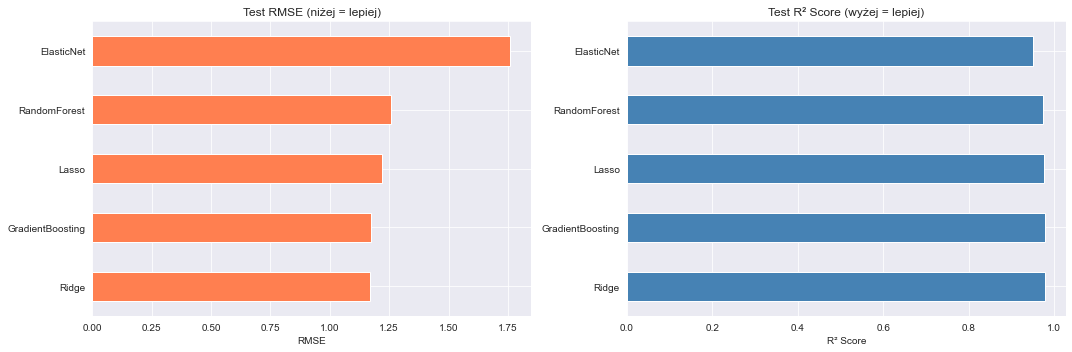

In [7]:
# Wizualizacja wyników
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Test RMSE
results_df['test_rmse'].plot(kind='barh', ax=axes[0], color='coral')
axes[0].set_title('Test RMSE (niżej = lepiej)')
axes[0].set_xlabel('RMSE')

# Test R²
results_df['test_r2'].plot(kind='barh', ax=axes[1], color='steelblue')
axes[1].set_title('Test R² Score (wyżej = lepiej)')
axes[1].set_xlabel('R² Score')

plt.tight_layout()
plt.show()


In [8]:
# Ważność cech w Random Forest
if best_name == 'RandomForest' or best_name == 'GradientBoosting':
    importance_df = get_feature_importance(best_model, X.columns, top_n=20)

    plt.figure(figsize=(10, 8))
    plt.barh(importance_df['feature'], importance_df['importance'], color='teal')
    plt.title(f'Top 20 Ważnych Cech - {best_name}')
    plt.xlabel('Importance')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

In [12]:
from pathlib import Path

# Aktualny katalog roboczy (miejsce uruchomienia notebooka)
notebooks_dir = Path.cwd()

# Folder "results" jest jeden poziom wyżej niż "notebooks"
results_dir = notebooks_dir.parent / "results"
results_dir.mkdir(parents=True, exist_ok=True)

results_file = results_dir / "modeling_results-02.csv"
results_file = results_file.resolve()

results_df.to_csv(results_file)
print(f"✓ Wyniki zapisane do: {results_file}")


✓ Wyniki zapisane do: C:\Users\aiszk\PycharmProjects\PythonProject\results\modeling_results-02.csv
